In [1]:
import matplotlib.pyplot as plt
import numpy as np
import time
import timeit

In [2]:
def function_1(x):
    return 2*(x**2) - 12 * x

def function_2(x):
    return 31.75*x**2 - 15.25*x + 2

In [3]:
def dichotomia(a:float, b:float, function, epsilon = 1e-6) -> float:
    delta = epsilon*0.01
    # counter = 0
    while b-a > epsilon:
        c = (a+b)/2
        x_1, x_2 = c - delta, c + delta
        
        if function(x_1) < function(x_2):
            b = x_2
            # print(b)
        if (function(x_1) > function(x_2)):

            a = x_1

        # counter+=1
            # print(a)
        # print(a, b)
    # print(counter)
    return (a+b)/2 , function((a+b)/2)


In [4]:
def quadratic_interpolation(x_1, function, delta_x = 1e-6, epsilon_1 = 1e-10, epsilon_2 = 1e-10):
    x_2 = x_1+delta_x
    x_3 = 0

    f1 = function(x_1)
    f2 = function(x_2)

    if function(x_1) > function(x_2):
        x_3 = x_1 + 2*delta_x
    if function(x_1) <= function(x_2):
        x_3 = x_1 - delta_x

    f3 = function(x_3)

    points = [(x_1, f1), (x_2, f2), (x_3, f3)]
    x_min, F_min = min(points, key=lambda p: p[1])


    
    up  = 0.5 * ((x_2**2 - x_3**2)*function(x_1) + (x_3**2 - x_1**2)*function(x_2) + (x_1**2 - x_2**2)*function(x_3))
    down = ((x_2 - x_3)*function(x_1) + (x_3 - x_1)*function(x_2) + (x_1 - x_2)*function(x_3))

    x_min_polynom = up / down
    f_x_min_polinom = function(x_min_polynom)

    condition_1 = abs((F_min - f_x_min_polinom) / f_x_min_polinom) < epsilon_1
    condition_2 = abs((x_min - x_min_polynom) / x_min_polynom) < epsilon_2

    if condition_1 and condition_2:
        return x_min_polynom, f_x_min_polinom

    interval_min = min(x_1, x_3)
    interval_max = max(x_1, x_3)

    if interval_min<=x_min_polynom<=interval_max:
        all_points = [(x_1, f1), (x_2, f2), (x_3, f3), (x_min_polynom, f_x_min_polinom)].sort(key=lambda p: p[0])

        min_index = min(range(4), key=lambda i: all_points)
        if min_index == 0:
                selected = all_points[0:3]
        elif min_index == 3:
            selected = all_points[1:4]
        else:
                # Сравниваем левого и правого соседа
                if all_points[min_index - 1][1] < all_points[min_index + 1][1]:
                    selected = all_points[min_index - 1:min_index + 2]
                else:
                    selected = all_points[min_index:min_index + 3]


        (x_1, f1), (x_2, f2), (x_3, f3) = selected

    else:
        x_1 = x_min
        f1 = f_x_min_polinom
        x_2 = x_1 + delta_x
        f2 = function(x_2)

    return x_min_polynom, f_x_min_polinom

In [5]:
%timeit dichotomia(0.1, 1000, function_1)

18.2 μs ± 585 ns per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


In [6]:
%timeit quadratic_interpolation(0.1, function_1)

3.71 μs ± 792 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


Text(0.5, 1.0, 'Первая функция 2x^2 - 12x')

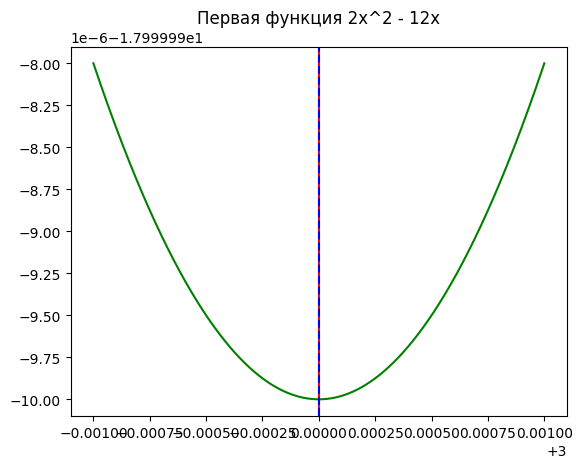

In [7]:
x = np.linspace(2.999, 3.001, 10000)
y_1 = function_1(x)
plt.plot(x, y_1, color = 'green')
plt.axvline(x=3, color='red', label='x = 3')
plt.axvline(x = dichotomia(0.1, 1000, function_1)[0], color = 'blue', linestyle = '--')
plt.title("Первая функция 2x^2 - 12x")

Text(0.5, 1.0, 'Первая функция 2x^2 - 12x')

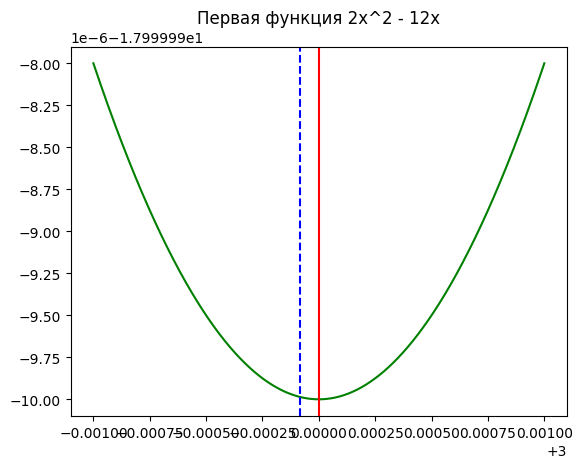

In [8]:
x = np.linspace(2.999, 3.001, 10000)
y_1 = function_1(x)
plt.plot(x, y_1, color = 'green')
plt.axvline(x=3, color='red', label='x = 3')
# plt.xlim(x.min(), x.max())
plt.axvline(x = quadratic_interpolation(0.1, function_1)[0], color = 'blue', linestyle = '--')
plt.title("Первая функция 2x^2 - 12x")

In [9]:
%timeit dichotomia(0.1, 100, function_2)

22.8 μs ± 1.33 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


In [10]:
%timeit quadratic_interpolation(-0.3, function_2)

5.19 μs ± 353 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


Text(0.5, 1.0, 'Вторая функция 31.75*x**2 - 15.25*x + 2')

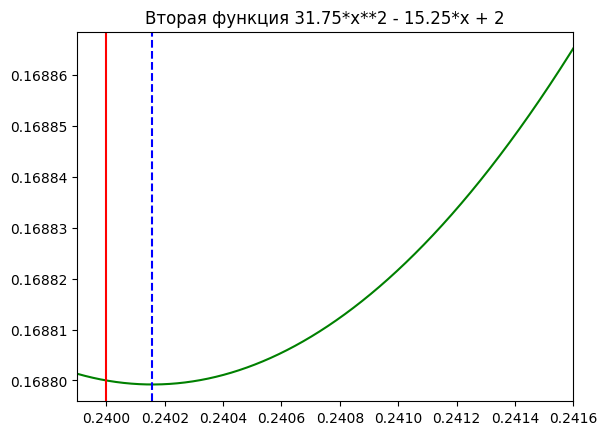

In [11]:
x = np.linspace(0.2399, 0.2416, 10000)
y_2 = function_2(x)
plt.plot(x, y_2, color = 'green')
plt.axvline(x=0.24, color='red')
plt.axvline(x = dichotomia(0, 1000, function_2)[0], color = 'blue', linestyle = '--')
plt.xlim(x.min(), x.max())
plt.title("Вторая функция 31.75*x**2 - 15.25*x + 2")

Text(0.5, 1.0, 'Вторая функция 31.75*x**2 - 15.25*x + 2')

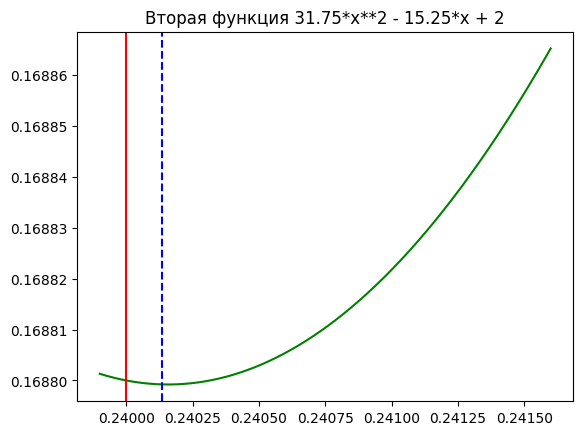

In [12]:
x = np.linspace(0.2399, 0.2416, 10000)
y_2 = function_2(x)
plt.plot(x, y_2, color = 'green')
plt.axvline(x=0.24, color='red')
plt.axvline(x = quadratic_interpolation(-0.3, function_2)[0], color = 'blue', linestyle = '--')
plt.title("Вторая функция 31.75*x**2 - 15.25*x + 2")